# Model-Free Reinforcement Learning: Monte Carlo and Temporal-Difference Control

This notebook implements and compares three model-free control algorithms:
1. **Monte Carlo Control**
2. **SARSA (On-Policy TD Control)**
3. **Q-Learning (Off-Policy TD Control)**
4. **Empirical Bias-Variance Analysis**


## Setup

In [1]:
!pip install torch matplotlib numpy tqdm --quiet

import torch
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from tqdm import tqdm
import random

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory Available: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

## 1. GridWorld Environment

A **5×5 GridWorld** with:
- **Walls** at (1,1), (2,3), (3,1) — agent stays in place on collision
- **Traps** at (1,3), (3,2) — reward **−5** per visit
- **Goal** at (4,4) — reward **+10**, episode ends
- All other steps: reward **−1**

In [2]:
class GridWorld:
    """5x5 GridWorld with walls and traps"""
    def __init__(self, size=5):
        self.size = size
        self.start_state = (0, 0)
        self.goal_state = (size - 1, size - 1)
        self.walls = [(1, 1), (2, 3), (3, 1)]
        self.traps = [(1, 3), (3, 2)]
        self.reset()

    def reset(self):
        self.state = self.start_state
        return self.state

    def step(self, action):
        """Actions: 0=up, 1=right, 2=down, 3=left"""
        x, y = self.state

        if action == 0:    # up
            nx, ny = max(0, x - 1), y
        elif action == 1:  # right
            nx, ny = x, min(self.size - 1, y + 1)
        elif action == 2:  # down
            nx, ny = min(self.size - 1, x + 1), y
        elif action == 3:  # left
            nx, ny = x, max(0, y - 1)

        if (nx, ny) in self.walls:
            nx, ny = x, y

        self.state = (nx, ny)

        if self.state == self.goal_state:
            return self.state, 10.0, True
        elif self.state in self.traps:
            return self.state, -5.0, False
        else:
            return self.state, -1.0, False

    def render(self, Q=None, title="GridWorld"):
        fig, ax = plt.subplots(figsize=(8, 8))
        action_arrows = {0: '^', 1: '>', 2: 'v', 3: '<'}

        for i in range(self.size):
            for j in range(self.size):
                if (i, j) in self.walls:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='black'))
                    ax.text(j + 0.5, i + 0.5, 'WALL', ha='center', va='center',
                            fontsize=9, color='white', weight='bold')
                elif (i, j) == self.goal_state:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='gold', edgecolor='black'))
                    ax.text(j + 0.5, i + 0.5, 'GOAL\n+10', ha='center', va='center',
                            fontsize=10, weight='bold')
                elif (i, j) in self.traps:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='darkorange', edgecolor='black'))
                    ax.text(j + 0.5, i + 0.3, 'TRAP\n-5', ha='center', va='center',
                            fontsize=9, weight='bold', color='white')
                    if Q is not None and (i, j) in Q:
                        q_values = Q[(i, j)]
                        if isinstance(q_values, torch.Tensor):
                            q_values = q_values.cpu().numpy()
                        best_action = np.argmax(q_values)
                        ax.text(j + 0.5, i + 0.7, action_arrows[best_action],
                                ha='center', va='center', fontsize=16, color='white')
                else:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='lightgray', edgecolor='black'))
                    if Q is not None and (i, j) in Q:
                        q_values = Q[(i, j)]
                        if isinstance(q_values, torch.Tensor):
                            q_values = q_values.cpu().numpy()
                        best_action = np.argmax(q_values)
                        best_value = q_values[best_action]
                        ax.text(j + 0.5, i + 0.4, action_arrows[best_action],
                                ha='center', va='center', fontsize=20, color='blue')
                        ax.text(j + 0.5, i + 0.75, f'{best_value:.1f}',
                                ha='center', va='center', fontsize=9, style='italic')

        ax.text(0.5, 0.05, 'START', ha='center', va='top', fontsize=7, color='gray')
        ax.set_xlim(0, self.size)
        ax.set_ylim(0, self.size)
        ax.set_aspect('equal')
        ax.invert_yaxis()
        ax.set_xticks([])
        ax.set_yticks([])
        plt.title(title)
        plt.tight_layout()
        return fig

env = GridWorld()
env.render()
plt.show()

<Figure size 800x800 with 1 Axes>

---
## 2. Monte Carlo Control

Monte Carlo control learns Q-values from **complete episodes** — no bootstrapping.

**Update rule:**
$$Q(s, a) \leftarrow Q(s, a) + \alpha [G_t - Q(s, a)]$$

where $G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \ldots$ is the actual return.

**Policy:** $\epsilon$-greedy — explore with probability $\epsilon$, otherwise take the greedy action.

In [3]:
class MonteCarloControl:
    """Monte Carlo Control with epsilon-greedy exploration"""
    def __init__(self, n_actions=4, gamma=0.99, alpha=0.1, epsilon=0.1, use_gpu=True):
        self.n_actions = n_actions
        self.gamma = gamma
        self.alpha = alpha
        self.epsilon = epsilon
        self.device = device if use_gpu else torch.device('cpu')
        self.Q = defaultdict(lambda: torch.zeros(n_actions, device=self.device))
        
    def epsilon_greedy_policy(self, state):
        if np.random.random() < self.epsilon:
            return np.random.randint(0, self.n_actions)
        else:
            return self.Q[state].argmax().item()
    
    def greedy_policy(self, state):
        return self.Q[state].argmax().item()
    
    def generate_episode(self, env, max_steps=200):
        episode = []
        state = env.reset()
        for _ in range(max_steps):
            action = self.epsilon_greedy_policy(state)
            next_state, reward, done = env.step(action)
            episode.append((state, action, reward))
            state = next_state
            if done:
                break
        return episode
    
    def update(self, episode):
        """Last-visit MC update (naive backward pass — not true first-visit)"""
        G = 0.0
        visited = set()
        
        for state, action, reward in reversed(episode):
            G = reward + self.gamma * G
            sa_pair = (state, action)
            if sa_pair not in visited:
                visited.add(sa_pair)
                old_q = self.Q[state][action].item()
                self.Q[state][action] += self.alpha * (G - old_q)
    
    def train(self, env, num_episodes=1000):
        episode_rewards = []
        for ep in tqdm(range(num_episodes), desc="MC Control Training"):
            episode = self.generate_episode(env)
            self.update(episode)
            total_reward = sum([r for _, _, r in episode])
            episode_rewards.append(total_reward)
            self.epsilon = max(0.01, self.epsilon * 0.995)
        return episode_rewards

### First-Visit vs Last-Visit MC

The naive backward pass above is actually **last-visit** MC: when iterating in reverse, the first time a `(state, action)` is encountered corresponds to its *last* occurrence in the episode.

A correct **first-visit** implementation accumulates returns in a dict (keyed by state-action), so later writes in the reverse pass overwrite earlier ones — leaving the return from the *first* chronological visit for each pair.

In [4]:
class MonteCarloControlFixed(MonteCarloControl):
    """Monte Carlo Control with correct first-visit MC update"""
    
    def update(self, episode):
        G = 0.0
        first_visit_returns = {}
        
        for state, action, reward in reversed(episode):
            G = reward + self.gamma * G
            first_visit_returns[(state, action)] = G  # last written in reverse = first chronologically
        
        for (state, action), G in first_visit_returns.items():
            old_q = self.Q[state][action].item()
            self.Q[state][action] += self.alpha * (G - old_q)

Training original MC (last-visit)...


MC Control Training:   0%|          | 0/5000 [00:00<?, ?it/s]


MC Control Training:   6%|▌         | 303/5000 [00:00<00:01, 3027.64it/s]


MC Control Training:  15%|█▌        | 768/5000 [00:00<00:01, 3956.70it/s]


MC Control Training:  24%|██▍       | 1209/5000 [00:00<00:00, 4161.82it/s]


MC Control Training:  34%|███▍      | 1713/5000 [00:00<00:00, 4498.05it/s]


... (16 outputs left out)

MC Control Training:  72%|███████▏  | 3576/5000 [00:00<00:00, 4448.40it/s]


MC Control Training:  82%|████████▏ | 4107/5000 [00:01<00:00, 4701.63it/s]


MC Control Training:  92%|█████████▏| 4597/5000 [00:01<00:00, 4758.85it/s]


MC Control Training: 100%|██████████| 5000/5000 [00:01<00:00, 4236.97it/s]


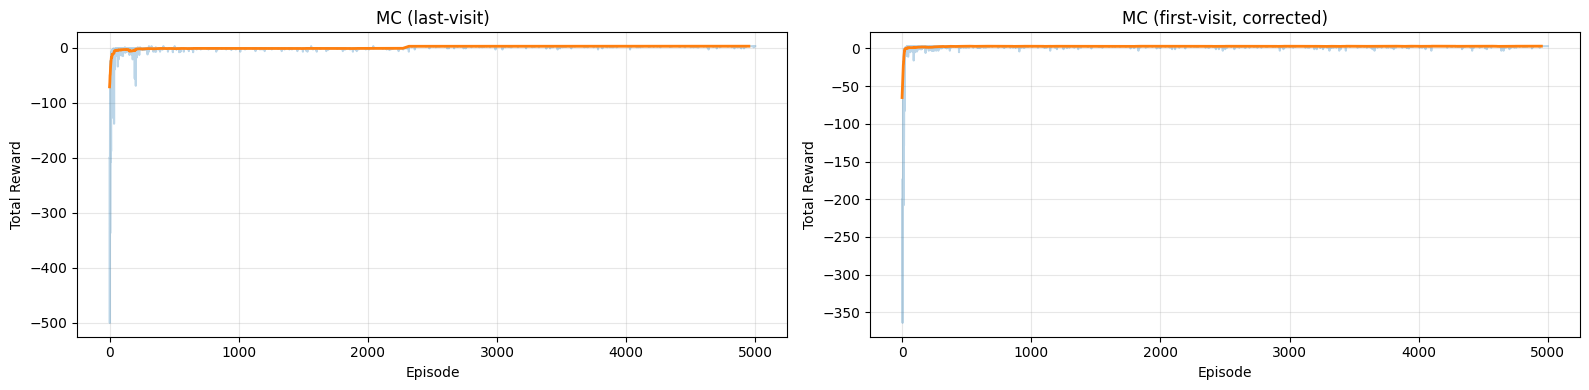

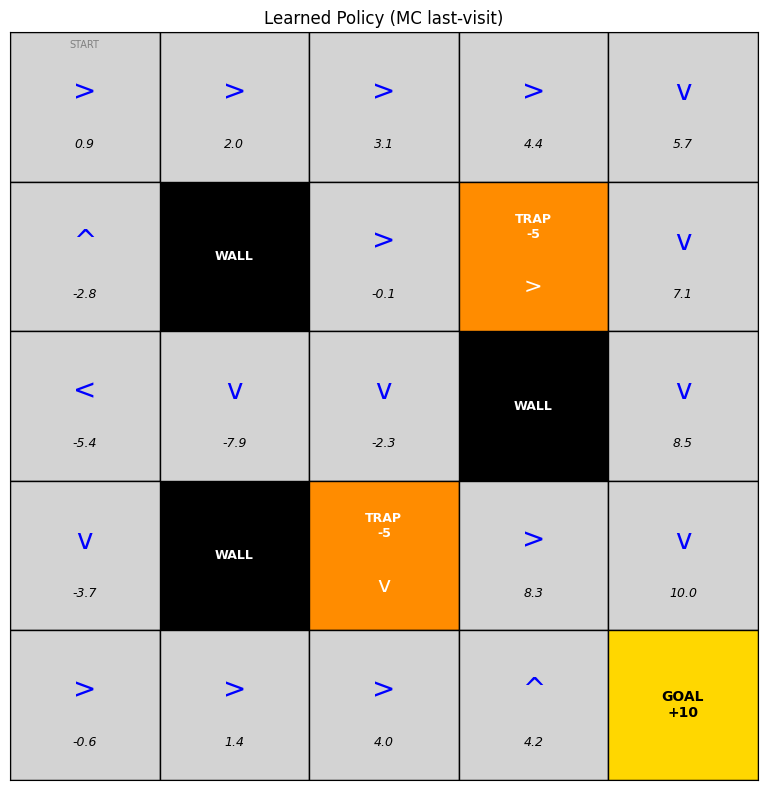

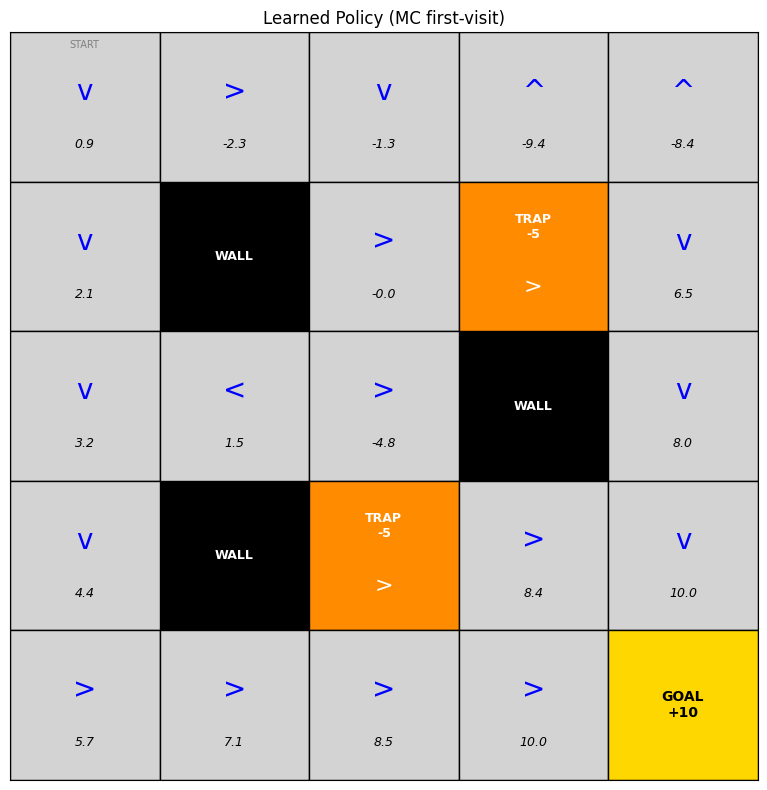

In [5]:
print('Training original MC (last-visit)...')
env_orig = GridWorld()
mc_orig = MonteCarloControl(gamma=0.95, alpha=0.1, epsilon=0.3)
rewards_mc_orig = mc_orig.train(env_orig, num_episodes=5000)

print('Training fixed MC (first-visit)...')
env = GridWorld()
mc = MonteCarloControlFixed(gamma=0.95, alpha=0.1, epsilon=0.3)
rewards_mc = mc.train(env, num_episodes=5000)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, rewards, label in [
    (axes[0], rewards_mc_orig, 'MC (last-visit)'),
    (axes[1], rewards_mc, 'MC (first-visit, corrected)'),
]:
    ax.plot(rewards, alpha=0.3)
    ax.plot(np.convolve(rewards, np.ones(50)/50, mode='valid'), linewidth=2)
    ax.set_xlabel('Episode')
    ax.set_ylabel('Total Reward')
    ax.set_title(label)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

env_orig.render(Q=mc_orig.Q, title='Learned Policy (MC last-visit)')
plt.show()
env.render(Q=mc.Q, title='Learned Policy (MC first-visit)')
plt.show()

---
## 3. SARSA — On-Policy TD Control

SARSA updates Q-values **every step** using the action actually taken by the policy:

$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \big[r_{t+1} + \gamma Q(s_{t+1}, a_{t+1}) - Q(s_t, a_t)\big]$$

The next action $a_{t+1}$ is sampled from the same $\epsilon$-greedy policy — making this **on-policy**.

In [6]:
class SARSA:
    """SARSA: On-policy TD Control"""
    def __init__(self, n_actions=4, gamma=0.99, alpha=0.1, epsilon=0.1, use_gpu=True):
        self.n_actions = n_actions
        self.gamma = gamma
        self.alpha = alpha
        self.epsilon = epsilon
        self.device = device if use_gpu else torch.device('cpu')
        self.Q = defaultdict(lambda: torch.zeros(n_actions, device=self.device))
        
    def epsilon_greedy(self, state):
        if np.random.random() < self.epsilon:
            return np.random.randint(0, self.n_actions)
        return self.Q[state].argmax().item()
    
    def greedy_policy(self, state):
        return self.Q[state].argmax().item()
    
    def update(self, state, action, reward, next_state, next_action, done):
        current_q = self.Q[state][action]
        if done:
            td_target = reward
        else:
            td_target = reward + self.gamma * self.Q[next_state][next_action]  # on-policy: uses actual next action
        td_error = td_target - current_q
        self.Q[state][action] += self.alpha * td_error
    
    def train(self, env, num_episodes=1000, max_steps=100):
        episode_rewards = []
        for ep in tqdm(range(num_episodes), desc="SARSA Training"):
            state = env.reset()
            action = self.epsilon_greedy(state)
            total_reward = 0
            for step in range(max_steps):
                next_state, reward, done = env.step(action)
                next_action = self.epsilon_greedy(next_state)
                self.update(state, action, reward, next_state, next_action, done)
                total_reward += reward
                state, action = next_state, next_action
                if done:
                    break
            episode_rewards.append(total_reward)
            self.epsilon = max(0.01, self.epsilon * 0.995)
        return episode_rewards

Training SARSA...


SARSA Training:   0%|          | 0/3000 [00:00<?, ?it/s]


SARSA Training:   3%|▎         | 85/3000 [00:00<00:03, 848.39it/s]


SARSA Training:  11%|█         | 318/3000 [00:00<00:01, 1718.53it/s]


SARSA Training:  19%|█▉        | 584/3000 [00:00<00:01, 2146.16it/s]


SARSA Training:  27%|██▋       | 799/3000 [00:00<00:01, 2047.84it/s]


... (6 outputs left out)

SARSA Training:  80%|████████  | 2412/3000 [00:01<00:00, 1986.80it/s]


SARSA Training:  89%|████████▊ | 2662/3000 [00:01<00:00, 2122.88it/s]


SARSA Training:  96%|█████████▋| 2893/3000 [00:01<00:00, 2174.27it/s]


SARSA Training: 100%|██████████| 3000/3000 [00:01<00:00, 2060.80it/s]


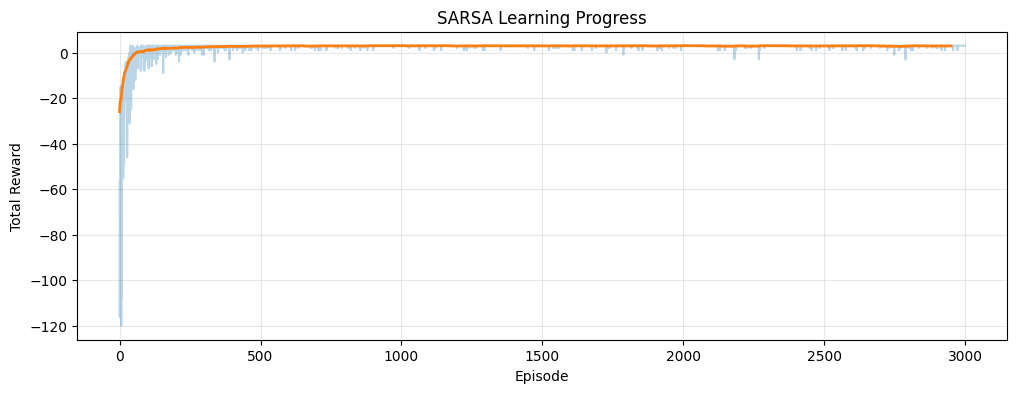

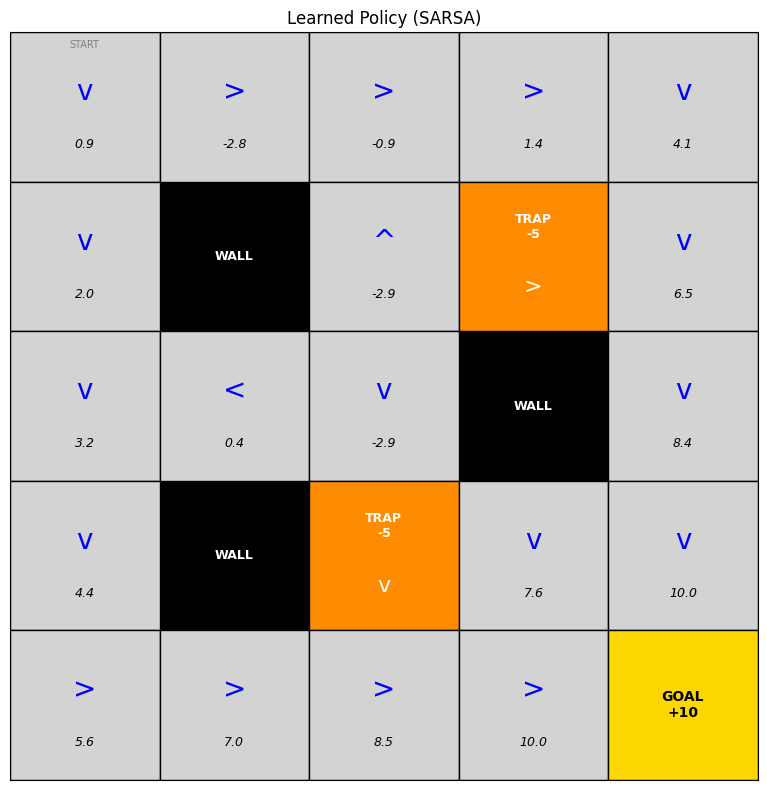

In [7]:
print('Training SARSA...')
env = GridWorld()
sarsa = SARSA(gamma=0.95, alpha=0.1, epsilon=0.3)
rewards_sarsa = sarsa.train(env, num_episodes=3000)

plt.figure(figsize=(12, 4))
plt.plot(rewards_sarsa, alpha=0.3)
plt.plot(np.convolve(rewards_sarsa, np.ones(50)/50, mode='valid'), linewidth=2)
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('SARSA Learning Progress')
plt.grid(True, alpha=0.3)
plt.show()

env.render(Q=sarsa.Q, title='Learned Policy (SARSA)')
plt.show()

---
## 4. Q-Learning — Off-Policy TD Control

Q-Learning uses the **maximum** Q-value for the next state, regardless of the action the behavior policy would take:

$$Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha \big[r_{t+1} + \gamma \max_a Q(s_{t+1}, a) - Q(s_t, a_t)\big]$$

This makes it **off-policy** — it learns the optimal policy even while exploring.

In [8]:
class QLearning:
    """Q-Learning: Off-policy TD Control"""
    def __init__(self, n_actions=4, gamma=0.99, alpha=0.1, epsilon=0.1, use_gpu=True):
        self.n_actions = n_actions
        self.gamma = gamma
        self.alpha = alpha
        self.epsilon = epsilon
        self.device = device if use_gpu else torch.device('cpu')
        self.Q = defaultdict(lambda: torch.zeros(n_actions, device=self.device))
        
    def epsilon_greedy(self, state):
        if np.random.random() < self.epsilon:
            return np.random.randint(0, self.n_actions)
        return self.Q[state].argmax().item()
    
    def greedy_policy(self, state):
        return self.Q[state].argmax().item()
    
    def update(self, state, action, reward, next_state, done):
        current_q = self.Q[state][action]
        if done:
            td_target = reward
        else:
            td_target = reward + self.gamma * self.Q[next_state].max()  # off-policy: max over all actions
        td_error = td_target - current_q
        self.Q[state][action] += self.alpha * td_error
    
    def train(self, env, num_episodes=1000, max_steps=100):
        episode_rewards = []
        for ep in tqdm(range(num_episodes), desc="Q-Learning Training"):
            state = env.reset()
            total_reward = 0
            for step in range(max_steps):
                action = self.epsilon_greedy(state)
                next_state, reward, done = env.step(action)
                self.update(state, action, reward, next_state, done)
                total_reward += reward
                state = next_state
                if done:
                    break
            episode_rewards.append(total_reward)
            self.epsilon = max(0.01, self.epsilon * 0.995)
        return episode_rewards

Training Q-Learning...


Q-Learning Training:   0%|          | 0/3000 [00:00<?, ?it/s]


Q-Learning Training:   3%|▎         | 97/3000 [00:00<00:03, 966.85it/s]


Q-Learning Training:  11%|█         | 332/3000 [00:00<00:01, 1778.06it/s]


Q-Learning Training:  18%|█▊        | 555/3000 [00:00<00:01, 1983.55it/s]


Q-Learning Training:  27%|██▋       | 823/3000 [00:00<00:00, 2256.16it/s]


... (5 outputs left out)

Q-Learning Training:  81%|████████  | 2428/3000 [00:01<00:00, 2615.22it/s]


Q-Learning Training:  90%|████████▉ | 2699/3000 [00:01<00:00, 2641.54it/s]


Q-Learning Training:  99%|█████████▉| 2969/3000 [00:01<00:00, 2657.56it/s]


Q-Learning Training: 100%|██████████| 3000/3000 [00:01<00:00, 2466.76it/s]


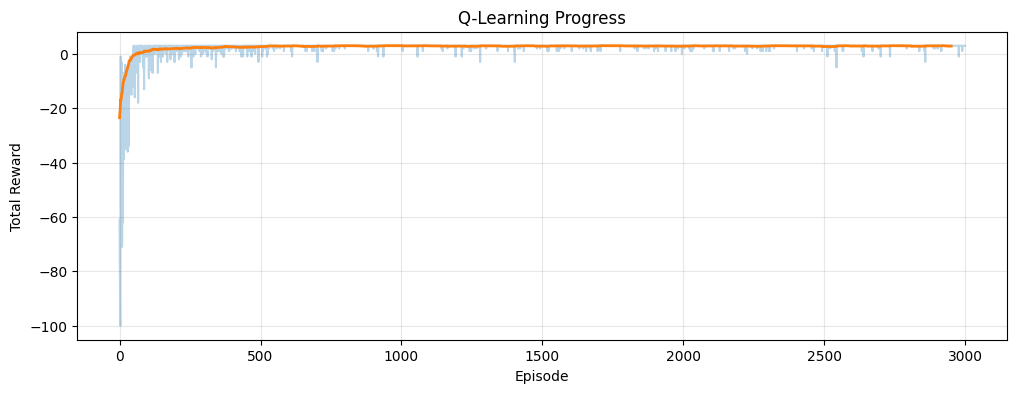

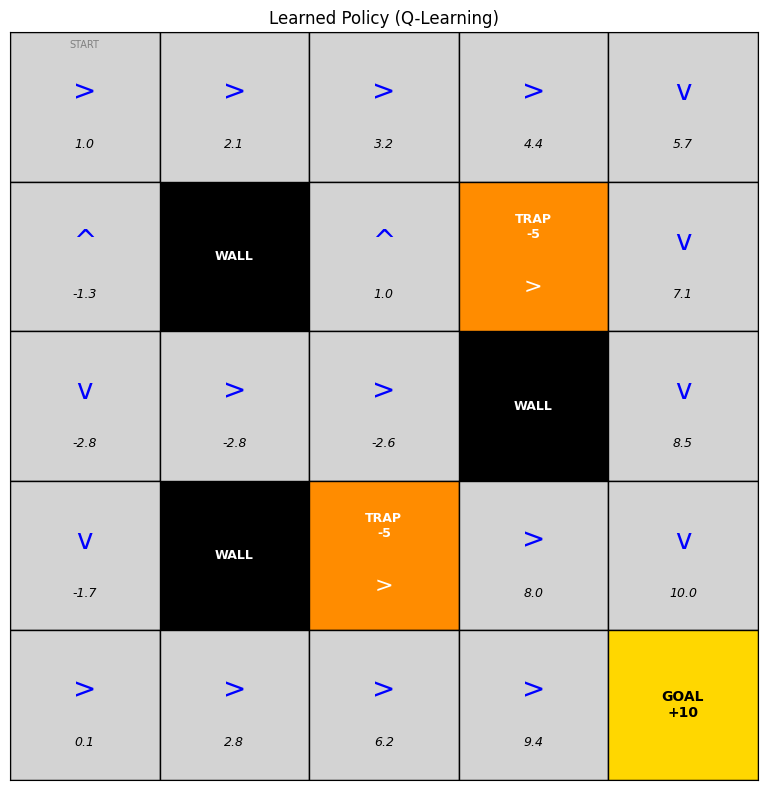

In [9]:
print('Training Q-Learning...')
env = GridWorld()
qlearning = QLearning(gamma=0.95, alpha=0.1, epsilon=0.3)
rewards_qlearning = qlearning.train(env, num_episodes=3000)

plt.figure(figsize=(12, 4))
plt.plot(rewards_qlearning, alpha=0.3)
plt.plot(np.convolve(rewards_qlearning, np.ones(50)/50, mode='valid'), linewidth=2)
plt.xlabel('Episode')
plt.ylabel('Total Reward')
plt.title('Q-Learning Progress')
plt.grid(True, alpha=0.3)
plt.show()

env.render(Q=qlearning.Q, title='Learned Policy (Q-Learning)')
plt.show()

---
## 5. Comparison: MC vs SARSA vs Q-Learning

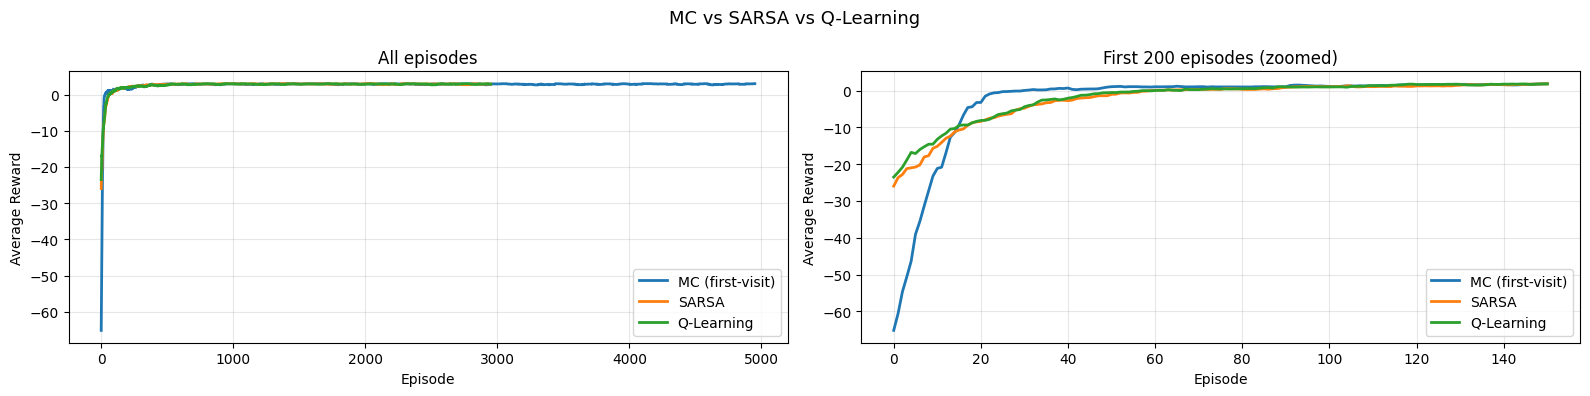

FINAL PERFORMANCE (Last 100 Episodes)
 Method                     Avg Reward
----------------------------------------
MC (first-visit)                  2.97
SARSA                             2.89
Q-Learning                        2.90


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
window = 50

for ax, max_ep in [(axes[0], None), (axes[1], 200)]:
    r_mc = rewards_mc[:max_ep] if max_ep else rewards_mc
    r_sarsa = rewards_sarsa[:max_ep] if max_ep else rewards_sarsa
    r_ql = rewards_qlearning[:max_ep] if max_ep else rewards_qlearning
    ax.plot(np.convolve(r_mc, np.ones(window)/window, mode='valid'), label='MC (first-visit)', linewidth=2)
    ax.plot(np.convolve(r_sarsa, np.ones(window)/window, mode='valid'), label='SARSA', linewidth=2)
    ax.plot(np.convolve(r_ql, np.ones(window)/window, mode='valid'), label='Q-Learning', linewidth=2)
    ax.set_xlabel('Episode')
    ax.set_ylabel('Average Reward')
    ax.set_title('All episodes' if not max_ep else f'First {max_ep} episodes (zoomed)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('MC vs SARSA vs Q-Learning', fontsize=13)
plt.tight_layout()
plt.show()

print('\n' + '='*70)
print('FINAL PERFORMANCE (Last 100 Episodes)')
print('='*70)
print(f"{' Method':<25} {'Avg Reward':>12}")
print('-'*40)
print(f"{'MC (first-visit)':<25} {np.mean(rewards_mc[-100:]):>12.2f}")
print(f"{'SARSA':<25} {np.mean(rewards_sarsa[-100:]):>12.2f}")
print(f"{'Q-Learning':<25} {np.mean(rewards_qlearning[-100:]):>12.2f}")

---
## 5b. Does Grid Size Affect MC vs TD Convergence?

A 10×10 grid forces longer episodes, which increases MC's variance disadvantage. We train all three on the larger grid and compare sample efficiency.

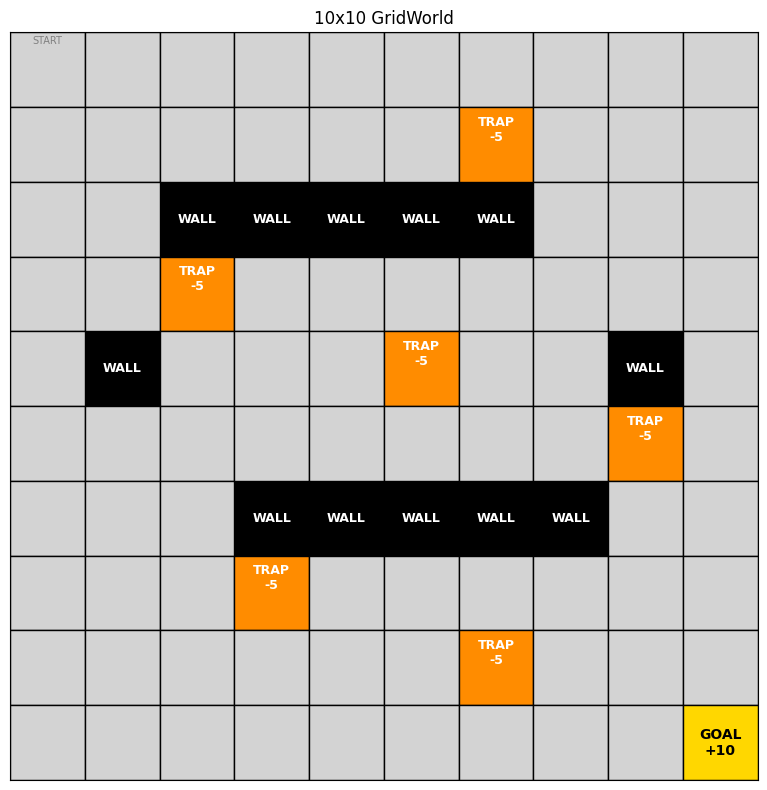

MC Training (steps):   0%|          | 0/100000 [00:00<?, ?it/s]


MC Training (steps):   2%|▏         | 2000/100000 [00:00<00:08, 11905.05it/s]


MC Training (steps):   4%|▍         | 4000/100000 [00:00<00:12, 7944.89it/s] 


MC Training (steps):   6%|▌         | 5515/100000 [00:00<00:15, 6004.15it/s]


MC Training (steps):   7%|▋         | 7125/100000 [00:01<00:16, 5621.15it/s]


MC Training (steps):   8%|▊         | 7774/100000 [00:01<00:21, 4383.75it/s]


... (161 outputs left out)

Q-Learning Training (steps):  92%|█████████▏| 45803/50000 [00:08<00:00, 17296.34it/s]


Q-Learning Training (steps):  95%|█████████▌| 47539/50000 [00:08<00:00, 17096.63it/s]


Q-Learning Training (steps):  99%|█████████▊| 49323/50000 [00:08<00:00, 17314.20it/s]


Q-Learning Training (steps): 50002it [00:08, 6041.10it/s]                            


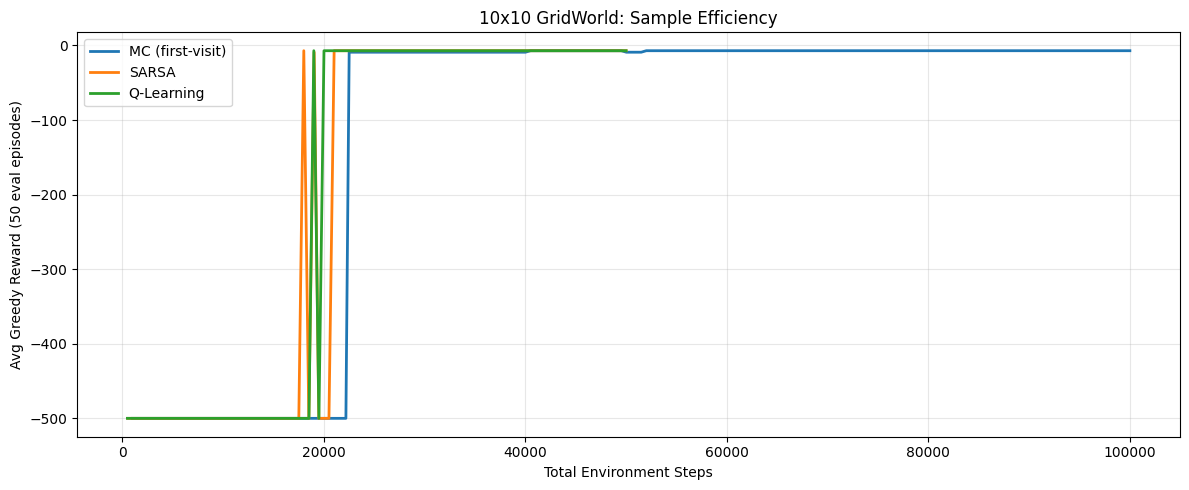

FINAL GREEDY POLICY PERFORMANCE
MC (first-visit)               -7.00
SARSA                          -7.00
Q-Learning                     -7.00


In [11]:
class GridWorld10x10(GridWorld):
    """10x10 GridWorld with two partial barriers forcing longer paths."""
    def __init__(self):
        self.size = 10
        self.start_state = (0, 0)
        self.goal_state = (9, 9)
        self.walls = [
            (2, 2), (2, 3), (2, 4), (2, 5), (2, 6),
            (6, 3), (6, 4), (6, 5), (6, 6), (6, 7),
            (4, 1), (4, 8),
        ]
        self.traps = [(1, 6), (3, 2), (4, 5), (5, 8), (7, 3), (8, 6)]
        self.reset()


def evaluate_policy(agent, n_eval=50, max_steps=500):
    total = 0
    for _ in range(n_eval):
        env = GridWorld10x10()
        state = env.reset()
        ep_reward = 0
        for _ in range(max_steps):
            action = agent.greedy_policy(state)
            state, reward, done = env.step(action)
            ep_reward += reward
            if done:
                break
        total += ep_reward
    return total / n_eval


def train_mc_with_eval(agent, eval_every=500, total_steps=1500000):
    env = GridWorld10x10()
    eval_rewards, eval_steps = [], []
    steps = 0
    next_eval = eval_every
    pbar = tqdm(total=total_steps, desc='MC Training (steps)')
    while steps < total_steps:
        episode = agent.generate_episode(env, max_steps=1000)
        agent.update(episode)
        agent.epsilon = max(0.01, agent.epsilon * 0.9995)
        steps += len(episode)
        pbar.update(len(episode))
        if steps >= next_eval:
            eval_rewards.append(evaluate_policy(agent))
            eval_steps.append(steps)
            next_eval += eval_every
    pbar.close()
    return eval_steps, eval_rewards


def train_sarsa_with_eval(agent, eval_every=500, total_steps=1500000, max_steps=100):
    env = GridWorld10x10()
    eval_rewards, eval_steps = [], []
    steps = 0
    next_eval = eval_every
    pbar = tqdm(total=total_steps, desc='SARSA Training (steps)')
    while steps < total_steps:
        state = env.reset()
        action = agent.epsilon_greedy(state)
        for _ in range(max_steps):
            next_state, reward, done = env.step(action)
            next_action = agent.epsilon_greedy(next_state)
            agent.update(state, action, reward, next_state, next_action, done)
            state, action = next_state, next_action
            steps += 1
            pbar.update(1)
            if done:
                break
        agent.epsilon = max(0.01, agent.epsilon * 0.995)
        if steps >= next_eval:
            eval_rewards.append(evaluate_policy(agent))
            eval_steps.append(steps)
            next_eval += eval_every
    pbar.close()
    return eval_steps, eval_rewards


def train_qlearning_with_eval(agent, eval_every=500, total_steps=1500000, max_steps=100):
    env = GridWorld10x10()
    eval_rewards, eval_steps = [], []
    steps = 0
    next_eval = eval_every
    pbar = tqdm(total=total_steps, desc='Q-Learning Training (steps)')
    while steps < total_steps:
        state = env.reset()
        for _ in range(max_steps):
            action = agent.epsilon_greedy(state)
            next_state, reward, done = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state
            steps += 1
            pbar.update(1)
            if done:
                break
        agent.epsilon = max(0.01, agent.epsilon * 0.995)
        if steps >= next_eval:
            eval_rewards.append(evaluate_policy(agent))
            eval_steps.append(steps)
            next_eval += eval_every
    pbar.close()
    return eval_steps, eval_rewards


env10 = GridWorld10x10()
env10.render(title='10x10 GridWorld')
plt.show()

TOTAL_STEPS = 100_000
TOTAL_STEPS_QUICK = 50_000
mc10    = MonteCarloControlFixed(gamma=0.99, alpha=0.05, epsilon=0.3)
sarsa10 = SARSA(gamma=0.99, alpha=0.1, epsilon=0.3)
ql10    = QLearning(gamma=0.99, alpha=0.1, epsilon=0.3)

steps_mc,    r_mc    = train_mc_with_eval(mc10,    total_steps=TOTAL_STEPS)
steps_sarsa, r_sarsa = train_sarsa_with_eval(sarsa10, total_steps=TOTAL_STEPS_QUICK)
steps_ql,    r_ql    = train_qlearning_with_eval(ql10, total_steps=TOTAL_STEPS_QUICK)

plt.figure(figsize=(12, 5))
plt.plot(steps_mc,    r_mc,    label='MC (first-visit)', linewidth=2)
plt.plot(steps_sarsa, r_sarsa, label='SARSA',            linewidth=2)
plt.plot(steps_ql,    r_ql,    label='Q-Learning',       linewidth=2)
plt.xlabel('Total Environment Steps')
plt.ylabel('Avg Greedy Reward (50 eval episodes)')
plt.title('10x10 GridWorld: Sample Efficiency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\n' + '='*50)
print('FINAL GREEDY POLICY PERFORMANCE')
print('='*50)
print(f"{'MC (first-visit)':<25} {r_mc[-1]:>10.2f}")
print(f"{'SARSA':<25} {r_sarsa[-1]:>10.2f}")
print(f"{'Q-Learning':<25} {r_ql[-1]:>10.2f}")

### Discussion: MC vs TD on Larger Grids

On the 5×5 grid, all three methods converge to comparable policies — episodes are short and MC's variance is manageable. On the 10×10 grid, MC requires more tuning (lower α, slower epsilon decay, longer episodes) to keep up with SARSA and Q-Learning, which work with identical hyperparameters from the small grid.

**Why:** Longer episodes inflate the variance of MC returns (more random variables summed). TD methods bootstrap — they update from a single reward + one estimated value — so variance stays low regardless of episode length. The cost is a small amount of bias, but for most practical problems this tradeoff favors TD.


---
## 6. SARSA vs Q-Learning on Cliff Walking

The **Cliff Walking** problem (Sutton & Barto, Example 6.6) is the classic demonstration of on-policy vs off-policy behavior.

- 4×10 grid, Start = bottom-left, Goal = bottom-right
- Stepping on the cliff: reward **−100**, reset to start
- **Optimal path**: along the cliff edge (shortest)
- **Safe path**: up and across the top (longer, no cliff risk)

Q-Learning learns the optimal (risky) path. SARSA learns the safe path because it accounts for the exploration noise that can randomly push the agent into the cliff.

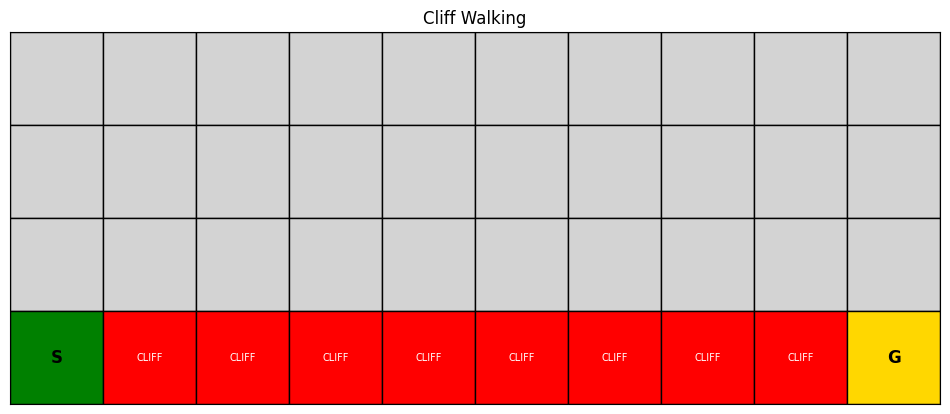

Cliff Walking Training:   0%|          | 0/500 [00:00<?, ?it/s]


Cliff Walking Training:   3%|▎         | 15/500 [00:00<00:03, 144.53it/s]


Cliff Walking Training:  12%|█▏        | 62/500 [00:00<00:01, 332.47it/s]


Cliff Walking Training:  25%|██▌       | 125/500 [00:00<00:00, 465.20it/s]


Cliff Walking Training:  38%|███▊      | 190/500 [00:00<00:00, 526.59it/s]


Cliff Walking Training:  49%|████▊     | 243/500 [00:00<00:00, 523.72it/s]


Cliff Walking Training:  60%|█████▉    | 298/500 [00:00<00:00, 531.21it/s]


Cliff Walking Training:  71%|███████   | 355/500 [00:00<00:00, 541.05it/s]


Cliff Walking Training:  82%|████████▏ | 410/500 [00:00<00:00, 464.53it/s]


Cliff Walking Training:  95%|█████████▌| 475/500 [00:00<00:00, 515.33it/s]


Cliff Walking Training: 100%|██████████| 500/500 [00:01<00:00, 491.49it/s]


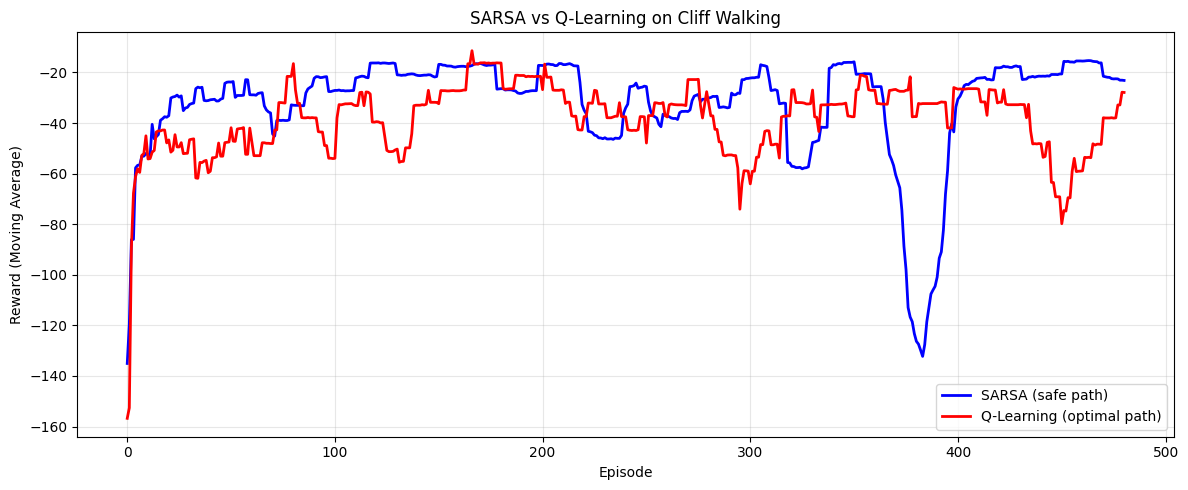

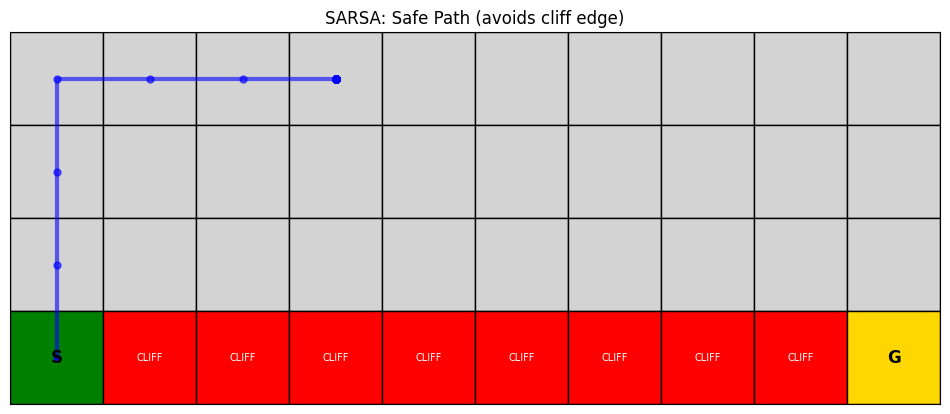

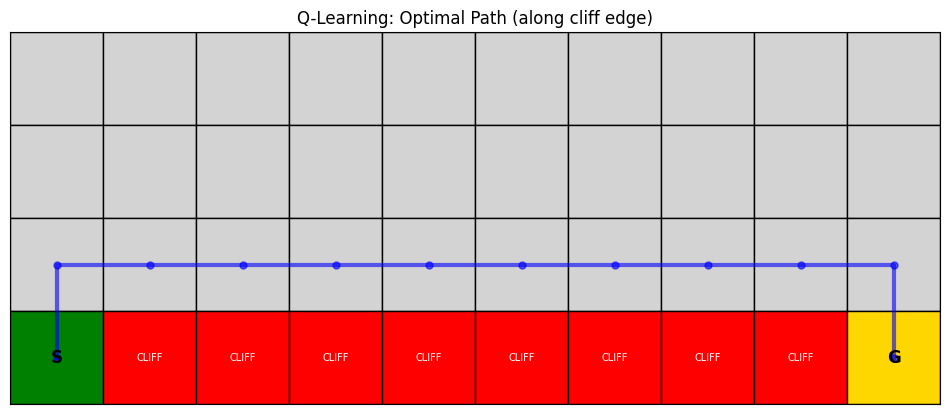

In [12]:
class CliffWalking:
    """Cliff Walking (Sutton & Barto Example 6.6)"""
    def __init__(self):
        self.rows = 4
        self.cols = 10
        self.start = (3, 0)
        self.goal = (3, 9)
        self.cliff = [(3, c) for c in range(1, 9)]
        self.reset()

    def reset(self):
        self.state = self.start
        return self.state

    def step(self, action):
        x, y = self.state
        if action == 0: x = max(0, x - 1)
        elif action == 1: y = min(self.cols - 1, y + 1)
        elif action == 2: x = min(self.rows - 1, x + 1)
        elif action == 3: y = max(0, y - 1)
        self.state = (x, y)
        if self.state in self.cliff:
            self.state = self.start
            return self.state, -100, False
        elif self.state == self.goal:
            return self.state, 0, True
        else:
            return self.state, -1, False

    def render(self, path=None, title="Cliff Walking"):
        fig, ax = plt.subplots(figsize=(12, 5))
        for i in range(self.rows):
            for j in range(self.cols):
                if (i, j) == self.start:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='green', edgecolor='black'))
                    ax.text(j + 0.5, i + 0.5, 'S', ha='center', va='center', fontsize=12, weight='bold')
                elif (i, j) == self.goal:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='gold', edgecolor='black'))
                    ax.text(j + 0.5, i + 0.5, 'G', ha='center', va='center', fontsize=12, weight='bold')
                elif (i, j) in self.cliff:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='red', edgecolor='black'))
                    ax.text(j + 0.5, i + 0.5, 'CLIFF', ha='center', va='center', fontsize=7, color='white')
                else:
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='lightgray', edgecolor='black'))
        if path:
            path_x = [p[1] + 0.5 for p in path]
            path_y = [p[0] + 0.5 for p in path]
            ax.plot(path_x, path_y, 'b-', linewidth=3, alpha=0.6, marker='o', markersize=5)
        ax.set_xlim(0, self.cols)
        ax.set_ylim(0, self.rows)
        ax.set_aspect('equal')
        ax.invert_yaxis()
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title)
        return fig

cliff_env = CliffWalking()
cliff_env.render()
plt.show()

sarsa_cliff = SARSA(gamma=0.99, alpha=0.5, epsilon=0.1)
ql_cliff = QLearning(gamma=0.99, alpha=0.5, epsilon=0.1)

rewards_sarsa_cliff = []
rewards_ql_cliff = []
for ep in tqdm(range(500), desc="Cliff Walking Training"):
    env = CliffWalking()
    state = env.reset()
    action = sarsa_cliff.epsilon_greedy(state)
    total_r = 0
    for _ in range(200):
        ns, r, done = env.step(action)
        na = sarsa_cliff.epsilon_greedy(ns)
        sarsa_cliff.update(state, action, r, ns, na, done)
        total_r += r
        state, action = ns, na
        if done: break
    rewards_sarsa_cliff.append(total_r)
    sarsa_cliff.epsilon = 0.1

    env = CliffWalking()
    state = env.reset()
    total_r = 0
    for _ in range(200):
        action = ql_cliff.epsilon_greedy(state)
        ns, r, done = env.step(action)
        ql_cliff.update(state, action, r, ns, done)
        total_r += r
        state = ns
        if done: break
    rewards_ql_cliff.append(total_r)
    ql_cliff.epsilon = 0.1

plt.figure(figsize=(12, 5))
window = 20
plt.plot(np.convolve(rewards_sarsa_cliff, np.ones(window)/window, mode='valid'),
         label='SARSA (safe path)', linewidth=2, color='blue')
plt.plot(np.convolve(rewards_ql_cliff, np.ones(window)/window, mode='valid'),
         label='Q-Learning (optimal path)', linewidth=2, color='red')
plt.xlabel('Episode')
plt.ylabel('Reward (Moving Average)')
plt.title('SARSA vs Q-Learning on Cliff Walking')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

def get_path(agent, env, max_steps=50):
    path = []
    state = env.reset()
    path.append(state)
    for _ in range(max_steps):
        action = agent.greedy_policy(state)
        state, _, done = env.step(action)
        path.append(state)
        if done: break
    return path

sarsa_path = get_path(sarsa_cliff, CliffWalking())
CliffWalking().render(path=sarsa_path, title='SARSA: Safe Path (avoids cliff edge)')
plt.show()

ql_path = get_path(ql_cliff, CliffWalking())
CliffWalking().render(path=ql_path, title='Q-Learning: Optimal Path (along cliff edge)')
plt.show()

---
## 7. Bias-Variance Analysis

Empirically measure the variance of Q-value estimates across independent runs for MC and Q-Learning.

Computing ground-truth Q-value (long Q-Learning run)...


Q-Learning Training:   0%|          | 0/50000 [00:00<?, ?it/s]


Q-Learning Training:   0%|          | 58/50000 [00:00<01:26, 578.40it/s]


Q-Learning Training:   1%|          | 265/50000 [00:00<00:34, 1452.21it/s]


Q-Learning Training:   1%|          | 538/50000 [00:00<00:24, 2032.62it/s]


Q-Learning Training:   2%|▏         | 813/50000 [00:00<00:21, 2314.88it/s]


... (797 outputs left out)

Q-Learning Training: 100%|█████████▉| 1999/2000 [00:00<00:00, 2651.42it/s]


Q-Learning Training: 100%|██████████| 2000/2000 [00:00<00:00, 2489.05it/s]


100%|██████████| 25/25 [00:48<00:00,  2.35s/it]


100%|██████████| 25/25 [00:48<00:00,  1.95s/it]


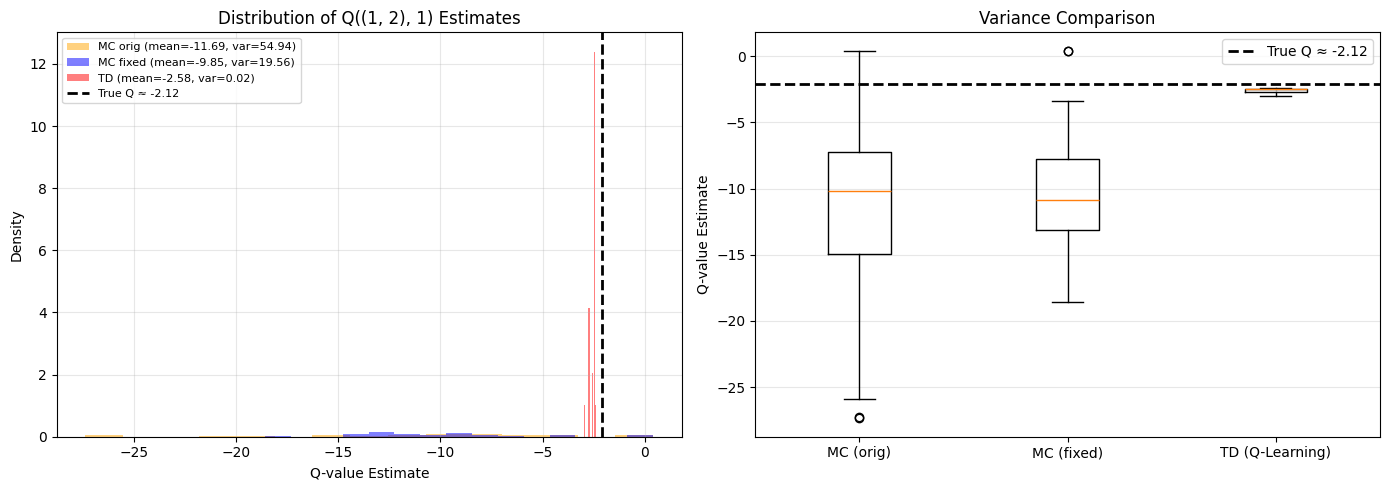

BIAS-VARIANCE RESULTS
Ground-truth Q-value: -2.1155
MC (last-visit):
  Mean: -11.6904  Bias: -9.5748  Variance: 54.9361
MC (first-visit):
  Mean: -9.8509  Bias: -7.7354  Variance: 19.5597
TD (Q-Learning):
  Mean: -2.5817  Bias: -0.4662  Variance: 0.0245


In [13]:
def compare_mc_td_variance(n_runs=25, n_episodes=2000):
    target_state_action = ((1, 2), 1)
    state, action = target_state_action

    print('Computing ground-truth Q-value (long Q-Learning run)...')
    true_agent = QLearning(gamma=0.95, alpha=0.05, epsilon=0.1)
    true_agent.train(GridWorld(), num_episodes=50000)
    true_q = true_agent.Q[state][action].item()
    print(f'Ground-truth Q{target_state_action} ≈ {true_q:.4f}\n')

    mc_orig_estimates = []
    mc_fixed_estimates = []
    td_estimates = []
    
    print(f'Running {n_runs} independent trials ({n_episodes} episodes each)...')
    for run in tqdm(range(n_runs)):
        mc_o = MonteCarloControl(gamma=0.95, alpha=0.1, epsilon=0.1)
        mc_o.train(GridWorld(), num_episodes=n_episodes)
        mc_orig_estimates.append(mc_o.Q[state][action].item())

        mc_f = MonteCarloControlFixed(gamma=0.95, alpha=0.1, epsilon=0.1)
        mc_f.train(GridWorld(), num_episodes=n_episodes)
        mc_fixed_estimates.append(mc_f.Q[state][action].item())
        
        td = QLearning(gamma=0.95, alpha=0.1, epsilon=0.1)
        td.train(GridWorld(), num_episodes=n_episodes)
        td_estimates.append(td.Q[state][action].item())
    
    mc_orig_estimates = np.array(mc_orig_estimates)
    mc_fixed_estimates = np.array(mc_fixed_estimates)
    td_estimates = np.array(td_estimates)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(mc_orig_estimates, bins=15, alpha=0.5,
                 label=f'MC orig (mean={mc_orig_estimates.mean():.2f}, var={mc_orig_estimates.var():.2f})', density=True, color='orange')
    axes[0].hist(mc_fixed_estimates, bins=15, alpha=0.5,
                 label=f'MC fixed (mean={mc_fixed_estimates.mean():.2f}, var={mc_fixed_estimates.var():.2f})', density=True, color='blue')
    axes[0].hist(td_estimates, bins=15, alpha=0.5,
                 label=f'TD (mean={td_estimates.mean():.2f}, var={td_estimates.var():.2f})', density=True, color='red')
    axes[0].axvline(true_q, color='black', linestyle='--', linewidth=2, label=f'True Q ≈ {true_q:.2f}')
    axes[0].set_xlabel('Q-value Estimate')
    axes[0].set_ylabel('Density')
    axes[0].set_title(f'Distribution of Q{target_state_action} Estimates')
    axes[0].legend(fontsize=8)
    axes[0].grid(True, alpha=0.3)
    
    axes[1].boxplot([mc_orig_estimates, mc_fixed_estimates, td_estimates],
                    labels=['MC (orig)', 'MC (fixed)', 'TD (Q-Learning)'])
    axes[1].axhline(true_q, color='black', linestyle='--', linewidth=2, label=f'True Q ≈ {true_q:.2f}')
    axes[1].set_ylabel('Q-value Estimate')
    axes[1].set_title('Variance Comparison')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()
    
    print('\n' + '='*70)
    print('BIAS-VARIANCE RESULTS')
    print('='*70)
    print(f'Ground-truth Q-value: {true_q:.4f}')
    for label, ests in [('MC (last-visit)', mc_orig_estimates),
                         ('MC (first-visit)', mc_fixed_estimates),
                         ('TD (Q-Learning)', td_estimates)]:
        bias = ests.mean() - true_q
        print(f'\n{label}:')
        print(f'  Mean: {ests.mean():.4f}  Bias: {bias:.4f}  Variance: {ests.var():.4f}')

compare_mc_td_variance()

---
## Summary

| Method | Bootstrapping | Update Freq | Bias | Variance | Policy Type |
|--------|---------------|-------------|------|----------|-------------|
| **Monte Carlo** | No | End of episode | Zero | High | Any |
| **SARSA** | Yes | Every step | Some | Low | On-policy |
| **Q-Learning** | Yes | Every step | Some | Low | Off-policy |

**Key takeaways:**
- MC has zero bias but high variance — needs more samples as environments grow
- TD methods trade a small bias for much lower variance → faster convergence
- SARSA is safer (accounts for exploration risk); Q-Learning finds the optimal policy
- Cliff Walking perfectly demonstrates SARSA's conservative vs Q-Learning's optimal behavior
